# Model Evaluation and Visualisation

Loads the three experiment result CSVs, standardises their columns, combines model results, calculates unweighted six-dataset means, and saves comparison CSVs and four plots.

### Cell 1 — Imports

Load the Python packages required by the notebook. `numpy`/`pandas` handle arrays and tables; `aeon` loads the time-series datasets and implements Rocket transforms; scikit-learn provides the Ridge classifier and evaluation metrics; timing and plotting utilities support benchmarking and visualisation.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

### Cell 2 — Configuration and paths

Set the experiment parameters and resolve the repository root. Result files are written to `results/Aarti/`; the path logic works when the notebook is opened from the repository root or a subfolder.

In [2]:
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in _candidates
     if (candidate / "results").is_dir()
     and (candidate / "hydra-authors-repo").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate the project root. Open this notebook from inside "
        "hydra-time-series-project, which must contain results/ and hydra-authors-repo/."
    )
RESULTS_DIR = PROJECT_ROOT / "results" / "Aarti"
PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
mini = pd.read_csv(RESULTS_DIR / "minirocket_results.csv")
multi = pd.read_csv(RESULTS_DIR / "multirocket_results.csv")
combined = pd.read_csv(RESULTS_DIR / "hydra_multirocket_results.csv")
mini_std = pd.DataFrame({
    "dataset": mini["dataset"],
    "model": "MiniRocket",
    "n_train": mini["n_train"],
    "n_test": mini["n_test"],
    "n_features": mini["n_features"],
    "accuracy": mini["accuracy"],
    "macro_f1": mini["macro_f1"],
    "total_training_time_seconds": mini["total_training_time_seconds"],
    "test_feature_extraction_time_seconds": mini["test_feature_extraction_time_seconds"],
    "prediction_time_seconds": mini["prediction_time_seconds"],
})


### Cell 3 — Top

Perform the next stage of the experiment or evaluation using the variables created in previous cells. Run cells in order because later cells depend on these definitions and results.

In [3]:
multi_std = pd.DataFrame({
    "dataset": multi["dataset"],
    "model": "MultiRocket",
    "n_train": multi["n_train"],
    "n_test": multi["n_test"],
    "n_features": multi["n_features"],
    "accuracy": multi["accuracy"],
    "macro_f1": multi["macro_f1"],
    "total_training_time_seconds": multi["total_training_time_seconds"],
    "test_feature_extraction_time_seconds": multi["test_feature_extraction_time_seconds"],
    "prediction_time_seconds": multi["prediction_time_seconds"],
})
combined_std = pd.DataFrame({
    "dataset": combined["dataset"],
    "model": "Hydra+MultiRocket",
    "n_train": combined["n_train"],
    "n_test": combined["n_test"],
    "n_features": combined["combined_features"],
    "accuracy": combined["accuracy"],
    "macro_f1": combined["macro_f1"],
    "total_training_time_seconds": combined["total_training_seconds"],
    "test_feature_extraction_time_seconds": (
        combined["hydra_test_transform_seconds"]
        + combined["multirocket_test_transform_seconds"]
    ),
    "prediction_time_seconds": combined["classifier_prediction_seconds"],
})
comparison = pd.concat([mini_std, multi_std, combined_std], ignore_index=True)
comparison["end_to_end_test_time_seconds"] = (
    comparison["test_feature_extraction_time_seconds"]
    + comparison["prediction_time_seconds"]
)
comparison["prediction_time_per_case_seconds"] = (
    comparison["prediction_time_seconds"] / comparison["n_test"]
)
dataset_order = ["Coffee", "ECG200", "GunPoint", "ItalyPowerDemand", "TwoLeadECG", "Wafer"]
model_order = ["MiniRocket", "MultiRocket", "Hydra+MultiRocket"]
comparison["dataset"] = pd.Categorical(comparison["dataset"], categories=dataset_order, ordered=True)


### Cell 4 — Top

Combine and standardise the three model result tables, sort them into a consistent order, and save/print the per-dataset comparison.

In [4]:
comparison["model"] = pd.Categorical(comparison["model"], categories=model_order, ordered=True)
comparison = comparison.sort_values(["dataset", "model"]).reset_index(drop=True)
output_csv = RESULTS_DIR / "model_comparison.csv"
comparison.to_csv(output_csv, index=False)
print("\nSIX-DATASET MODEL COMPARISON")
print("=" * 110)
columns = [
    "dataset", "model", "n_features", "accuracy", "macro_f1",
    "total_training_time_seconds", "end_to_end_test_time_seconds"
]
print(comparison[columns].round(4).to_string(index=False))
print(f"\nSaved comparison CSV: {output_csv}")
summary = comparison.groupby("model", observed=False)[
    ["accuracy", "macro_f1", "total_training_time_seconds", "end_to_end_test_time_seconds"]
].mean().reindex(model_order)
summary_file = RESULTS_DIR / "model_comparison_mean_summary.csv"
summary.to_csv(summary_file)
print("\nUNWEIGHTED MEAN ACROSS THE SIX DATASETS")
print(summary.round(4).to_string())
print(f"Saved mean summary: {summary_file}")


SIX-DATASET MODEL COMPARISON
         dataset             model  n_features  accuracy  macro_f1  total_training_time_seconds  end_to_end_test_time_seconds
          Coffee        MiniRocket        9996    1.0000    1.0000                       0.8094                        0.0223
          Coffee       MultiRocket       49728    1.0000    1.0000                       0.5245                        0.3362
          Coffee Hydra+MultiRocket       55872    1.0000    1.0000                       3.5612                        0.9856
          ECG200        MiniRocket        9996    0.8900    0.8783                       0.0951                        0.0251
          ECG200       MultiRocket       49728    0.9100    0.9017                       0.5483                        0.3650
          ECG200 Hydra+MultiRocket       53824    0.9100    0.9017                       1.4139                        1.1000
        GunPoint        MiniRocket        9996    0.9933    0.9933                      

### Cell 5 — Define the plotting function

This function creates one grouped bar chart comparing all three models across the six datasets. It saves a high-resolution PNG in `results/Aarti/plots/` **and displays the figure directly below the code cell** in the notebook. Closing the figure after display prevents plots from accumulating in memory.


In [5]:
def grouped_chart(metric, title, ylabel, filename, ylim=None):
    """Create a comparison chart, save it as PNG, and display it in the notebook."""
    pivot = comparison.pivot(index="dataset", columns="model", values=metric)
    pivot = pivot.reindex(index=dataset_order, columns=model_order)

    ax = pivot.plot(kind="bar", figsize=(11, 6))
    ax.set_title(title)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)
    if ylim:
        ax.set_ylim(*ylim)
    ax.legend(title="Model")

    plt.tight_layout()
    output = PLOTS_DIR / filename
    plt.savefig(output, dpi=300, bbox_inches="tight")
    print(f"Saved chart: {output}")

    # Display the figure immediately beneath this cell in Jupyter.
    plt.show()
    plt.close()


### Cell 6 — Generate and display the comparison plots

Run this cell to create four charts: accuracy, macro F1-score, total training time, and end-to-end test time. Each chart is both saved to the repository's `results/Aarti/plots/` folder and displayed inline in this notebook, so the plots are visible to anyone who opens the executed notebook.


Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\accuracy_by_dataset.png


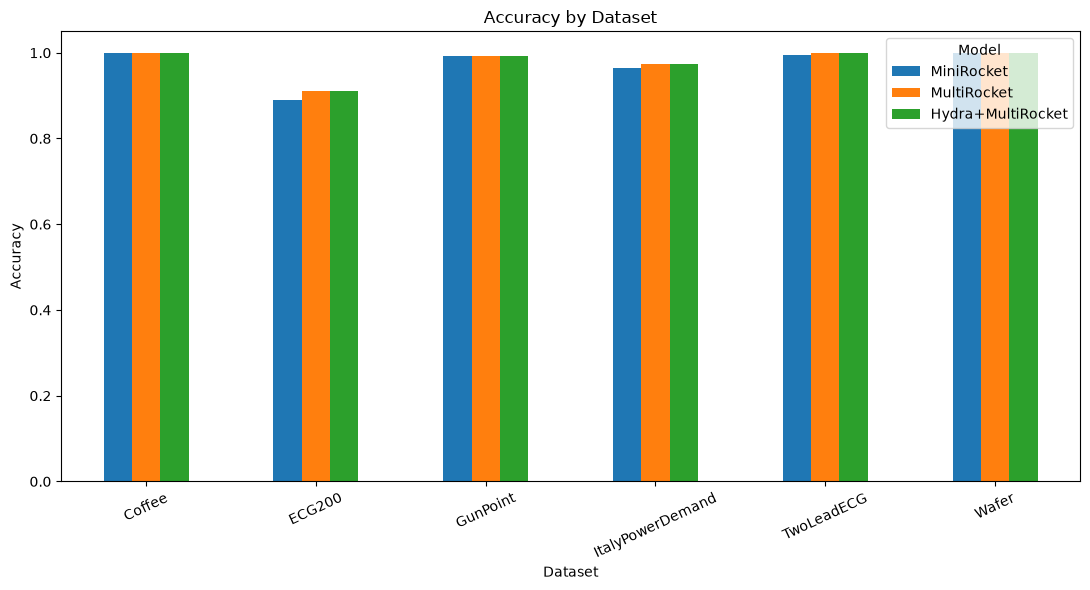

Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\macro_f1_by_dataset.png


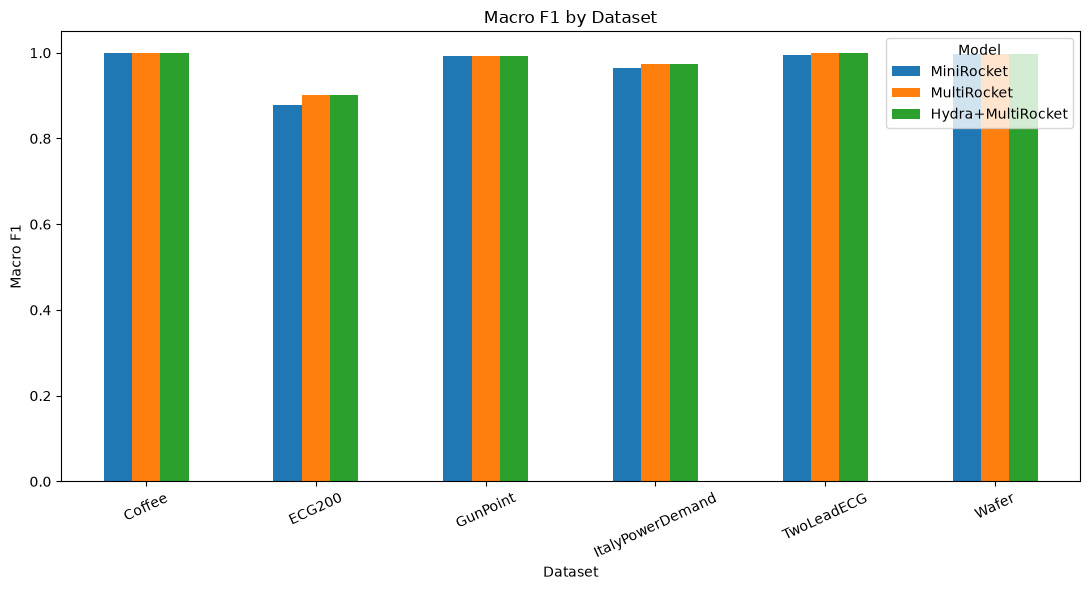

Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\training_time_by_dataset.png


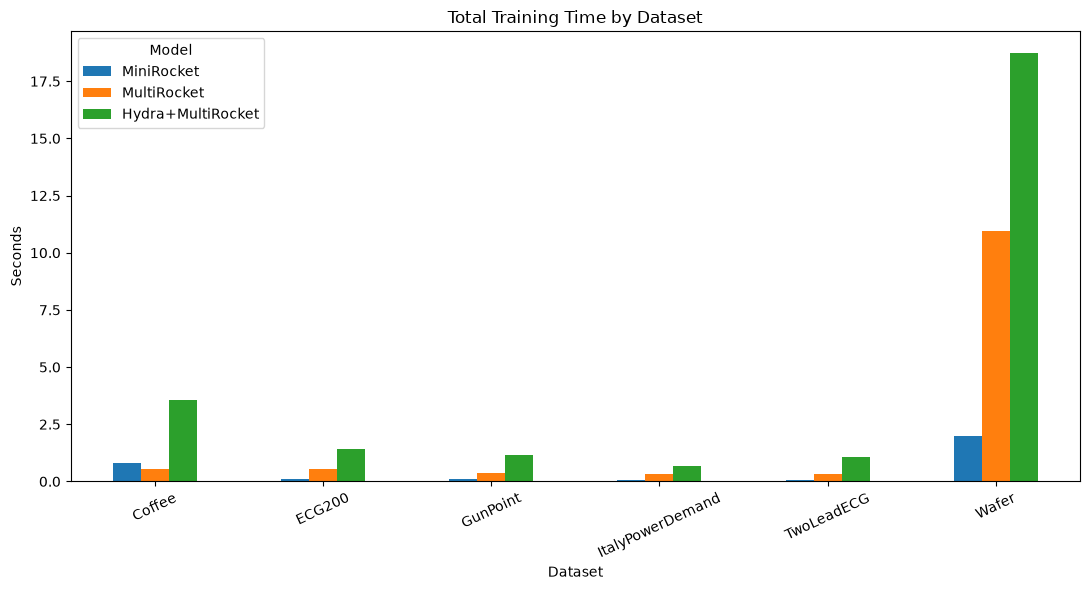

Saved chart: c:\Users\Aarti\Documents\GitHub\hydra-time-series-project\results\Aarti\plots\end_to_end_test_time_by_dataset.png


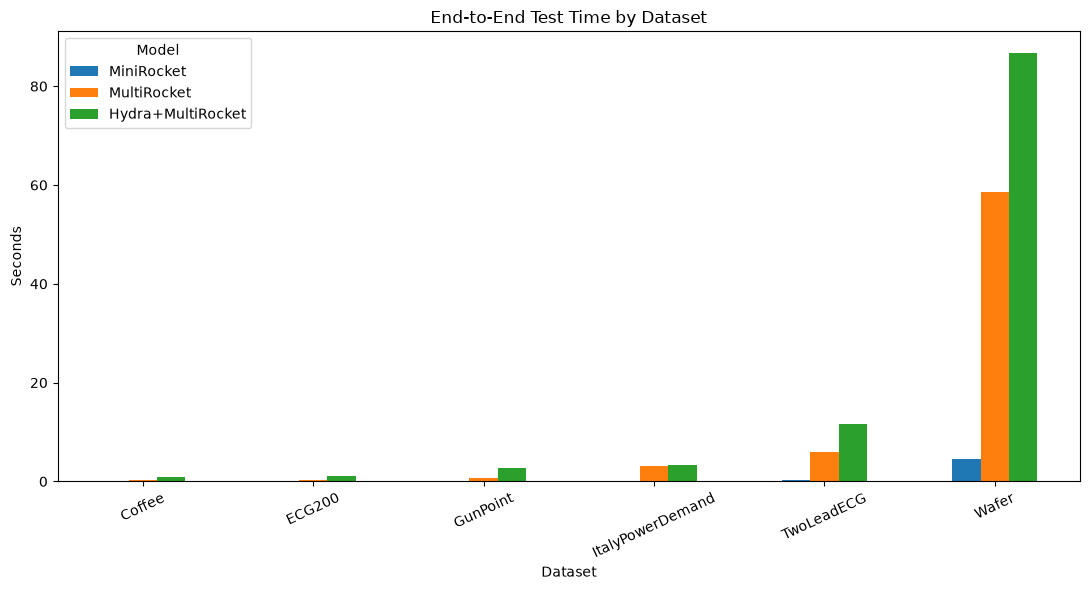


Note: timing comparisons are most meaningful when all runs use the same machine,
environment, and non-concurrent execution. End-to-end test time includes feature
extraction plus classifier prediction for all three models.


In [6]:
grouped_chart(
    "accuracy", "Accuracy by Dataset", "Accuracy",
    "accuracy_by_dataset.png", ylim=(0, 1.05)
)

grouped_chart(
    "macro_f1", "Macro F1 by Dataset", "Macro F1",
    "macro_f1_by_dataset.png", ylim=(0, 1.05)
)

grouped_chart(
    "total_training_time_seconds", "Total Training Time by Dataset",
    "Seconds", "training_time_by_dataset.png"
)

grouped_chart(
    "end_to_end_test_time_seconds", "End-to-End Test Time by Dataset",
    "Seconds", "end_to_end_test_time_by_dataset.png"
)

print("\nNote: timing comparisons are most meaningful when all runs use the same machine,")

print("environment, and non-concurrent execution. End-to-end test time includes feature")

print("extraction plus classifier prediction for all three models.")
